# 03 — ARIMA Forecasting and Traditional Model Evaluation

## 1. Research objective and motivation

Can a classical statistical model improve the next-session NVIDIA closing-price forecast beyond **persistence**, $\hat C_{t+1}=C_t$? ARIMA provides an interpretable benchmark that models linear dependence in historical prices and forecast innovations. It helps distinguish the value of fitted temporal structure from simply carrying forward the latest price.

The target is **Yahoo split-adjusted Close in USD**, on the project's retrospective split basis without dividend adjustment. Forecasts are issued after each origin session closes. Training uses **2015–2022**; validation uses **2023–2024**. A session is an actual NASDAQ trading session, including half-days. No weekend or holiday prices are manufactured.

This investigation connects training-data characteristics, a bounded AIC selection, model fitting, rolling forecasts and their errors. It reproduces the **recorded ARIMA(2,1,2) fit only**, using the production function, and reuses the saved nine-candidate search evidence. It does not conduct another order search, change settings or overwrite experiment records. **Reserved 2025 quote values and performance are not loaded.**

Run all cells in order with the project environment from the repository or `notebooks/` directory. The frozen snapshot and original `artifacts/arima_v1/` and `artifacts/naive_v1/` evidence must be available locally. Important outputs and figures remain inline; no extra artifacts are exported.


In [1]:
from pathlib import Path
import hashlib
import json
import warnings
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown, display
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.gofplots import qqplot
from market_forecasting.data import snapshot_provenance, load_yahoo_snapshot
from market_forecasting.calendar import audit_sessions
from market_forecasting.dataset import build_development_dataset, naive_predictions, error_metrics
from market_forecasting.arima import select_training_model, rolling_one_step

ROOT = Path.cwd() if (Path.cwd() / "configs/nvda.json").exists() else Path.cwd().parent
config_path, settings_path = ROOT / "configs/nvda.json", ROOT / "configs/arima.json"
config, settings = json.loads(config_path.read_text()), json.loads(settings_path.read_text())
START, TRAIN_END, VALIDATION_END = map(pd.Timestamp, [config["start"], config["train_end"], config["validation_end"]])
assert (START, TRAIN_END, VALIDATION_END) == tuple(pd.to_datetime(["2015-01-01", "2022-12-31", "2024-12-31"]))
assert config["target_ticker"] == "NVDA" and config["price_convention"] == "split_adjusted_close"
assert settings["selection"] == "training_aic" and settings["trend"] == "n" and settings["refit"] is False
assert settings["orders"] == [[p, 1, q] for p in range(3) for q in range(3)]
assert settings["maxiter"] == 500 and settings["calendar"] == "NASDAQ"

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2})
pd.set_option("display.max_columns", 12)
BLUE, ORANGE, GREEN = "#2563eb", "#d97706", "#059669"


def dated_axis(ax, first, last):
    """Format the permitted plotted interval with readable date labels."""
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_xlim(first, last)


def show_figure(fig):
    """Display a figure inline without exporting a separate file."""
    plt.show()
    plt.close(fig)


# The acquisition record is checked through identifiers, without parsing full-period statistics.
raw_path = ROOT / "data/raw/NVDA_yahoo_snapshot.json"
provenance = snapshot_provenance(raw_path, ROOT / "docs/data_verification.json", "NVDA")
training = load_yahoo_snapshot(raw_path, start=config["start"], end=config["train_end"])["close"]
training_audit = audit_sessions(training.index, config["start"], config["train_end"], settings["calendar"])
assert not training_audit["missing"] and not training_audit["unexpected"]
assert training_audit["ordered"] and training_audit["duplicate_dates"] == 0
run_dir = ROOT / "artifacts/arima_v1"
summary = json.loads((run_dir / "summary.json").read_text())
assert summary == json.loads((ROOT / "docs/arima_validation_v1.json").read_text())
assert summary["test_evaluated"] is False and pd.Timestamp(summary["validation_end"]) <= VALIDATION_END
assert summary["snapshot_sha256"] == provenance["sha256"]
assert summary["config_sha256"] == hashlib.sha256(config_path.read_bytes()).hexdigest()
assert summary["arima_config_sha256"] == hashlib.sha256(settings_path.read_bytes()).hexdigest()
assert summary["config"] == config and summary["arima_settings"] == settings
assert len(training) == summary["training_rows"]
assert str(training.index.min().date()) == summary["training_start"]
assert str(training.index.max().date()) == summary["training_end"]
display(pd.Series({"snapshot_identity_verified": provenance["checksum_matches"],
                   "training_observations": len(training), "first_training_session": training.index.min().date(),
                   "last_training_session": training.index.max().date(), "calendar_gaps": len(training_audit["missing"]),
                   "recorded_experiment_utc": summary["created_at_utc"], "statsmodels": version("statsmodels")},
                  name="Research inputs").to_frame())


,Research inputs
snapshot_identity_verified,True
training_observations,2014
first_training_session,2015-01-02
last_training_session,2022-12-30
calendar_gaps,0
recorded_experiment_utc,2026-10-13T09:23:17.489222+00:00
statsmodels,0.15.0


## 2. Understanding ARIMA

Let $C_t$ denote the closing price, $w_t=\Delta C_t$ its first difference, and $\varepsilon_t$ a model innovation: the unexpected part of an observation after accounting for information available before it.

- **Autoregressive (AR):** explain the current series value using its own lags, for example $w_t=\phi_1w_{t-1}+\varepsilon_t$.
- **Integrated (I):** difference the observed level $d$ times before modelling its temporal dependence. With $d=1$, $w_t=C_t-C_{t-1}$. Forecasting the next level then adds the forecast difference to the latest observed level.
- **Moving-average errors (MA):** model dependence on earlier innovations, for example $w_t=\varepsilon_t+\theta_1\varepsilon_{t-1}$. Innovations are estimated during fitting/filtering; they are not directly observed price columns.

For illustration, an ARIMA(1,1,1) without drift has
\[
w_{t+1}=\phi_1w_t+\theta_1\varepsilon_t+\varepsilon_{t+1},\qquad
\hat C_{t+1|t}=C_t+\phi_1w_t+\theta_1\hat\varepsilon_t.
\]
The forecast uses a conditional mean of zero for the unknown future innovation **under the fitted model**. It does not know tomorrow's error.

**MA is not SMA.** An SMA technical indicator averages observed prices over a window. An ARIMA MA term weights past model innovations. The two operations have different inputs and purposes.


In [2]:
# A small arithmetic example illustrates the equation; these are not NVIDIA estimates.
toy_close, toy_change, toy_innovation = 100., 2., -1.
toy_phi, toy_theta = .4, .3
toy_components = pd.Series({"AR contribution (USD)": toy_phi * toy_change,
                            "MA contribution (USD)": toy_theta * toy_innovation})
display(toy_components.to_frame("Illustrative contribution"))
print(f"Predicted change: {toy_components.sum():.2f} USD")
print(f"Reconstructed next Close: {toy_close + toy_components.sum():.2f} USD")


,Illustrative contribution
AR contribution (USD),0.8
MA contribution (USD),-0.3


Predicted change: 0.50 USD
Reconstructed next Close: 100.50 USD


The AR term contributes **0.80 USD**, the MA term contributes **−0.30 USD**, and the illustrative forecast is **100.50 USD**. This small calculation explains the components; the research forecasts below come from the actual reusable ARIMA implementation.

## 3. Examining time-series characteristics

A weakly stationary process has a constant mean and finite variance, with autocovariance depending on lag rather than calendar position. Changing price levels, trends and variability can challenge this description. Autocorrelation measures association between a series and its own past; strong level autocorrelation can arise from persistent levels without implying useful prediction of the next change.

We first inspect annual training summaries. The means and standard deviations are descriptive properties of historical subsamples, not estimates proving a stable or unstable data-generating process. All diagnostics in Sections 3–8 use **training observations only**. Validation performance cannot determine their settings.


In [3]:
changes = training.diff().dropna()
training_years = training.groupby(training.index.year).agg(observations="size", mean_close_usd="mean", sd_close_usd="std")
training_years["mean_change_usd"] = changes.groupby(changes.index.year).mean()
training_years["sd_change_usd"] = changes.groupby(changes.index.year).std()
display(training_years.round(6))
display(Markdown(
    f"Mean training Close changes from **{training_years.mean_close_usd.iloc[0]:.4f} USD** "
    f"in {training_years.index[0]} to **{training_years.mean_close_usd.iloc[-1]:.4f} USD** "
    f"in {training_years.index[-1]}. Dollar-change SD changes from "
    f"**{training_years.sd_change_usd.iloc[0]:.6f}** to **{training_years.sd_change_usd.iloc[-1]:.6f} USD**. "
    "Differencing may reduce level persistence while leaving substantial variation in the scale of changes."
))


,observations,mean_close_usd,sd_close_usd,mean_change_usd,sd_change_usd
date,,,,,
2015,252,0.592956,0.103222,0.001278,0.012902
2016,252,1.344030,0.545098,0.007319,0.047589
2017,251,3.744593,0.951339,0.008641,0.090642
2018,251,5.809604,0.912500,-0.005976,0.166237
2019,252,4.364692,0.624698,0.010099,0.105286
2020,253,9.890709,2.932400,0.028350,0.315032
2021,252,19.521993,5.870683,0.064905,0.620238
2022,251,18.568956,4.641280,-0.058952,0.766600


Mean training Close changes from **0.5930 USD** in 2015 to **18.5690 USD** in 2022. Dollar-change SD changes from **0.012902** to **0.766600 USD**. Differencing may reduce level persistence while leaving substantial variation in the scale of changes.

### Complementary stationarity diagnostics

We fix four descriptive tests: ADF and KPSS on Close and on its first difference, each with a constant and no deterministic time trend. ADF uses at most 20 augmenting lags, selected by its internal AIC; KPSS uses its automatic bandwidth. These diagnostic lag choices are **not** the ARIMA order search.

| Diagnostic | Null hypothesis | Interpretation at the illustrative 5% threshold |
|---|---|---|
| ADF | The series has a unit root | A small p-value is evidence against that null under the test specification |
| KPSS (`regression="c"`) | The series is stationary around a constant | A small p-value is evidence against level stationarity |

Failure to reject is not proof of a null. Results depend on deterministic terms, lag choices, sample length, breaks and volatility behaviour. Neither test establishes constant variance or forecasting skill. The fixed `d=1` benchmark is assessed in this light; these diagnostics do not trigger an automatic change in specification. [ADF documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html), [KPSS documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html).


In [4]:
diagnostic_rows, diagnostic_warnings = [], []
for label, series in [("Close", training), ("First dollar difference", changes)]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        adf_result = adfuller(series, maxlag=20, regression="c", autolag="AIC", result_object=False)
        kpss_result = kpss(series, regression="c", nlags="auto", result_object=False)
    diagnostic_rows.extend([
        {"series": label, "test": "ADF", "statistic": adf_result[0],
         "p_value_or_bound": f"{adf_result[1]:.6g}", "lags": adf_result[2],
         "reject_null_at_5pct": adf_result[1] < .05},
        {"series": label, "test": "KPSS", "statistic": kpss_result[0],
         "p_value_or_bound": ("< 0.01" if kpss_result[1] == .01 else "> 0.10" if kpss_result[1] == .1 else f"{kpss_result[1]:.6g}"),
         "lags": kpss_result[2], "reject_null_at_5pct": kpss_result[1] < .05},
    ])
    diagnostic_warnings.extend({"series": label, "warning": str(w.message)} for w in caught)
stationarity_table = pd.DataFrame(diagnostic_rows)
display(stationarity_table)
display(pd.DataFrame(diagnostic_warnings))


,series,test,statistic,p_value_or_bound,lags,reject_null_at_5pct
0,Close,ADF,-1.125532,0.704783,17,False
1,Close,KPSS,5.427195,< 0.01,28,True
2,First dollar difference,ADF,-9.354115,8.14618e-16,20,True
3,First dollar difference,KPSS,0.080609,> 0.10,5,False


,series,warning
0,Close,The test statistic is outside of the range of ...
1,First dollar difference,The test statistic is outside of the range of ...


**Interpretation.** The level ADF test does not reject a unit root (p ≈ 0.705), while KPSS rejects level stationarity (p < 0.01). For first differences, ADF rejects a unit root and KPSS does not reject level stationarity (p > 0.10). Together these results are consistent with first differencing as a useful benchmark treatment of level persistence. They do **not** show that differenced dollar changes have constant volatility or are independent.

The KPSS p-values lie beyond its tabulated range; the warning messages are retained and the bounds are reported instead of treating 0.01 and 0.10 as exact probabilities. These diagnostics provide qualified evidence, not a unique model specification.

## 4. Differencing

First differencing is the dollar-change calculation:
\[
\Delta C_t=C_t-C_{t-1}.
\]
It differs from a percentage return, $100(C_t/C_{t-1}-1)$, and a log return, $\log(C_t/C_{t-1})$. All describe movement, but only the first retains USD units without dividing by the preceding price.

`Series.diff()` aligns each difference to its **later** observation. The initial value is undefined because no preceding price exists inside the permitted series; removing that single diagnostic value does not impute data or modify the source snapshot. ARIMA receives the **original Close levels** with `d=1`. Feeding manually differenced values into that same specification would difference twice and change the target interpretation.


,previous_close_usd,close_usd,difference_usd,return_pct,log_return
date,,,,,
2015-01-05,0.50325,0.49475,-0.00850,-1.689023,-0.017035
2015-01-06,0.49475,0.47975,-0.01500,-3.031831,-0.030787
2015-01-07,0.47975,0.47850,-0.00125,-0.260552,-0.002609
2015-01-08,0.47850,0.49650,0.01800,3.761751,0.036927
2015-01-09,0.49650,0.49850,0.00200,0.402821,0.004020


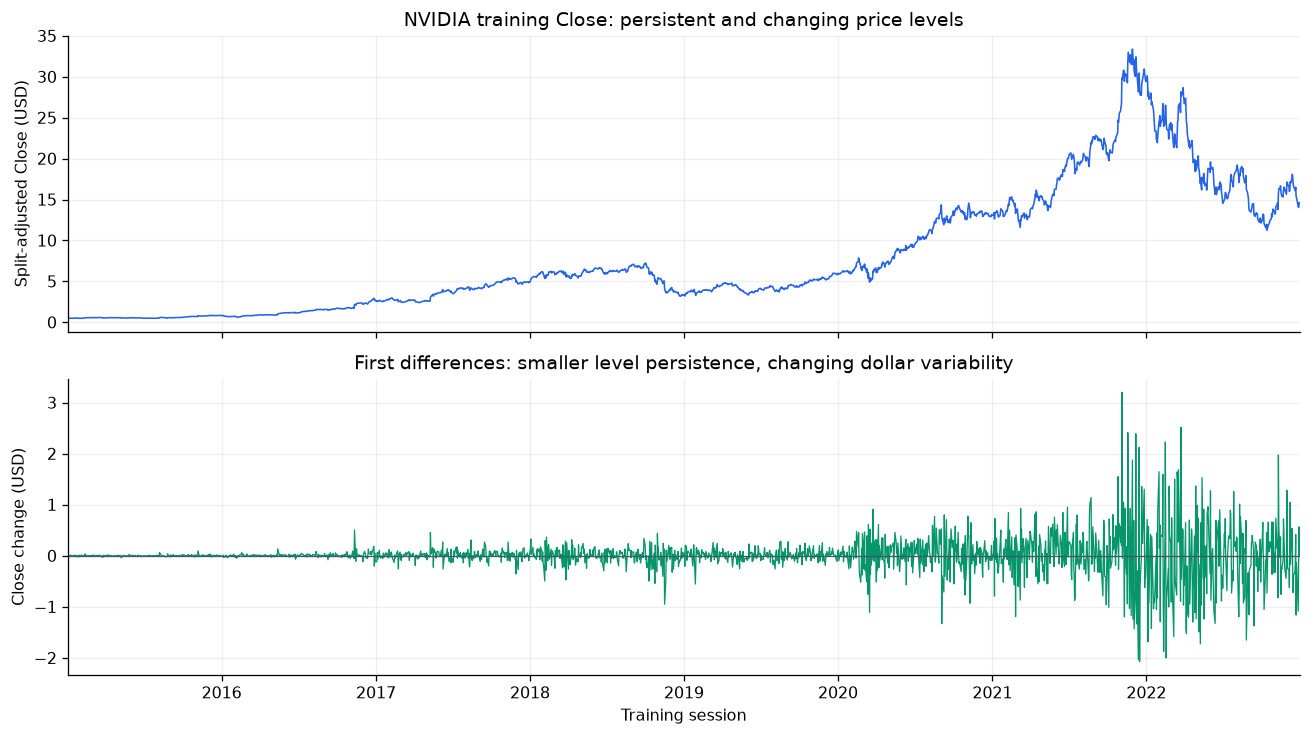

In [5]:
change_example = pd.DataFrame({"previous_close_usd": training.shift(1), "close_usd": training,
                               "difference_usd": training.diff(),
                               "return_pct": 100 * training.pct_change(fill_method=None),
                               "log_return": np.log(training / training.shift(1))}).iloc[1:6]
display(change_example.round(8))
assert len(changes) == len(training) - 1
np.testing.assert_array_equal(changes.to_numpy(), np.diff(training.to_numpy()))
fig, axes = plt.subplots(2, 1, figsize=(11.5, 6.5), sharex=True)
axes[0].plot(training.index, training, color=BLUE, linewidth=1)
axes[0].set(title="NVIDIA training Close: persistent and changing price levels", ylabel="Split-adjusted Close (USD)")
axes[1].plot(changes.index, changes, color=GREEN, linewidth=.8)
axes[1].axhline(0, color="#475569", linewidth=.8)
axes[1].set(title="First differences: smaller level persistence, changing dollar variability", xlabel="Training session", ylabel="Close change (USD)")
dated_axis(axes[1], training.index.min(), training.index.max())
fig.tight_layout(); show_figure(fig)


The differenced plot fluctuates around a much smaller scale than the level series, but its spread increases substantially across the training interval. Differencing and variance stabilisation are different operations. A log transformation or a volatility model would define a different benchmark and is not silently substituted here.

## 5. Autocorrelation and partial autocorrelation

For a stationary series $w$, the lag-$k$ autocorrelation is $\rho_k=\operatorname{Corr}(w_t,w_{t-k})$. The ACF describes overall linear lag association. The PACF at lag $k$ describes the remaining linear association after accounting for intervening lags $1,\ldots,k-1$.

For the unadjusted sample ACF used here, with $z_t=w_t-\bar w$:
\[
\hat\rho_k=\frac{\sum_{t=k+1}^{n}z_tz_{t-k}}{\sum_{t=1}^{n}z_t^2}.
\]
We verify lag one with a small mathematical calculation and use the library for the full diagnostics. PACF uses the explicit `ywm` estimator. All plots use a fixed 30-session lag horizon. The level ACF is descriptive and has no inferential band. Difference-series bands are approximate **pointwise** 95% intervals; inspecting many lags and nonconstant volatility limit their interpretation. [ACF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.acf.html), [PACF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.pacf.html).


,lag_sessions,Close_ACF,difference_ACF,difference_PACF
0,1,0.998310,-0.044967,-0.044967
1,2,0.996731,-0.026750,-0.028830
2,3,0.995250,0.022040,0.019561
3,4,0.993709,-0.034420,-0.033388
4,5,0.992190,0.059271,0.057588


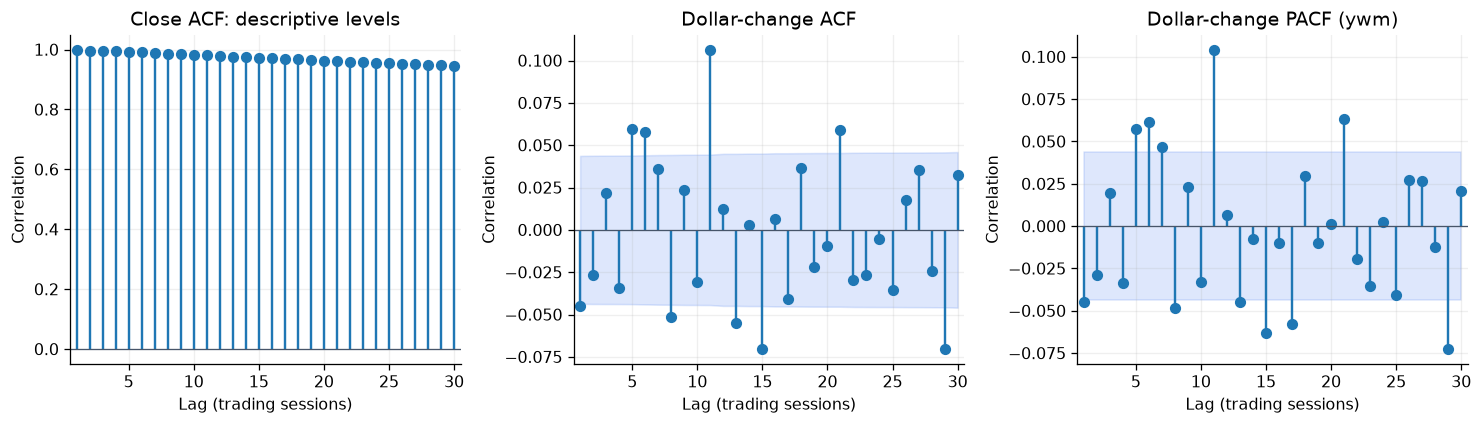

Lag-one Close ACF is **0.998310**, versus **-0.044967** for dollar changes. Persistence in the level is much stronger than the first-lag association in changes. The mixed, relatively small change-series correlations do not uniquely identify p or q.

In [6]:
LAGS = 30
level_acf = acf(training, nlags=LAGS, adjusted=False, fft=True, result_object=False)
difference_acf, difference_acf_ci = acf(changes, nlags=LAGS, adjusted=False, fft=True, alpha=.05, result_object=False)
difference_pacf, difference_pacf_ci = pacf(changes, nlags=LAGS, method="ywm", alpha=.05, result_object=False)
z = changes.to_numpy() - changes.mean()
manual_lag_one = np.dot(z[1:], z[:-1]) / np.dot(z, z)
np.testing.assert_allclose(manual_lag_one, difference_acf[1], rtol=0, atol=1e-12)
display(pd.DataFrame({"lag_sessions": np.arange(1, 6), "Close_ACF": level_acf[1:6],
                      "difference_ACF": difference_acf[1:6], "difference_PACF": difference_pacf[1:6]}))


def correlation_panel(ax, values, intervals, title):
    """Plot calculated lag associations and optional zero-centred interval bands."""
    lags = np.arange(1, len(values))
    ax.stem(lags, values[1:], basefmt=" ", linefmt="C0-", markerfmt="C0o")
    if intervals is not None:
        ax.fill_between(lags, intervals[1:, 0] - values[1:], intervals[1:, 1] - values[1:], color=BLUE, alpha=.15)
    ax.axhline(0, color="#475569", linewidth=.8)
    ax.set(title=title, xlabel="Lag (trading sessions)", ylabel="Correlation", xlim=(.5, LAGS + .5))


fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
correlation_panel(axes[0], level_acf, None, "Close ACF: descriptive levels")
correlation_panel(axes[1], difference_acf, difference_acf_ci, "Dollar-change ACF")
correlation_panel(axes[2], difference_pacf, difference_pacf_ci, "Dollar-change PACF (ywm)")
fig.tight_layout(); show_figure(fig)
display(Markdown(
    f"Lag-one Close ACF is **{level_acf[1]:.6f}**, versus **{difference_acf[1]:.6f}** "
    "for dollar changes. Persistence in the level is much stronger than the first-lag association "
    "in changes. The mixed, relatively small change-series correlations do not uniquely identify p or q."
))


For idealised pure AR or pure MA processes, ACF/PACF patterns can suggest candidate orders. A finite, changing financial series with mixed AR and MA dynamics need not show a clean cutoff. A spike is neither causal evidence nor an instruction to expand the search. The bounded candidate set below remains the comparison protocol; these diagnostics clarify its assumptions and limitations.

## 6. ARIMA model specification

In $ARIMA(p,d,q)$, $p$ counts autoregressive lags, $d$ counts differences and $q$ counts lagged innovations. These are **model-order hyperparameters**, not the coefficients estimated from observations. Increasing $p$ or $q$ adds fitted relationships and can increase estimation uncertainty. Changing $d$ changes the transformation and may remove useful structure or leave persistence untreated.

Our selected $ARIMA(2,1,2)$ without drift is
\[
\Delta C_t=\phi_1\Delta C_{t-1}+\phi_2\Delta C_{t-2}
+\varepsilon_t+\theta_1\varepsilon_{t-1}+\theta_2\varepsilon_{t-2}.
\]
Thus a one-step price forecast adds the predicted dollar change to $C_t$. The model estimates four lag coefficients and an innovation-variance parameter, $\sigma^2$. It has no SMA feature, deterministic drift, seasonal terms or market-context regressors.

`trend="n"` fixes the no-drift specification. Stationarity and invertibility constraints apply to the ARMA structure of the **differenced** process; they do not make the original price levels stationary. The implementation constructs a state-space ARIMA model on levels and estimates its parameters by likelihood optimisation. [Model specification](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html).


In [7]:
selected_order = tuple(summary["selected_order"])
assert selected_order == (2, 1, 2)
specification = pd.DataFrame({"component": ["AR order p", "Differences d", "MA order q", "Deterministic trend", "Optimizer cap", "Rolling coefficient refit"],
                              "setting": [selected_order[0], selected_order[1], selected_order[2], settings["trend"], settings["maxiter"], settings["refit"]],
                              "role": ["Two lagged dollar changes", "One difference of Close", "Two lagged innovations",
                                       "No drift", "Maximum likelihood optimizer iterations", "Disabled; only state is updated"]})
display(specification)


,component,setting,role
0,AR order p,2,Two lagged dollar changes
1,Differences d,1,One difference of Close
2,MA order q,2,Two lagged innovations
3,Deterministic trend,n,No drift
4,Optimizer cap,500,Maximum likelihood optimizer iterations
5,Rolling coefficient refit,False,Disabled; only state is updated


## 7. Candidate models and AIC selection

The candidate set is $p,q\in\{0,1,2\}$ with $d=1$, no drift and a maximum of 500 optimiser iterations. `select_training_model()` fits candidates on training prices only, records warnings/failures, excludes nonconverged or nonfinite fits, and selects the lowest eligible training AIC. Exact AIC ties prefer lower $p+q$, then lexicographic order. The iteration cap is not an LSTM epoch count.

Akaike Information Criterion balances likelihood fit and parameter count:
\[
AIC=2k-2\log(\hat L).
\]
Here $k$ includes the estimated innovation variance as well as lag coefficients. A lower value is preferred among these comparable likelihood specifications, but it is neither a validation MAE nor a guarantee of future accuracy.

The table and plot use the **saved nine-candidate evidence**, checked against the configured orders and selection rule. We do not rerun or enlarge that search. The next section reproduces the already selected order to expose its fitted parameters and execute the actual rolling algorithm.


,order,eligible,converged,aic,warnings,delta_AIC,selected
0,"(2, 1, 2)",True,True,1756.733879,Non-invertible starting MA parameters found. U...,0.000000,True
1,"(2, 1, 1)",True,True,1758.120968,None,1.387089,False
2,"(1, 1, 2)",True,True,1758.441066,Non-invertible starting MA parameters found. U...,1.707186,False
3,"(0, 1, 1)",True,True,1763.374946,None,6.641066,False
4,"(1, 1, 0)",True,True,1763.599055,None,6.865176,False
5,"(2, 1, 0)",True,True,1763.968673,None,7.234794,False
6,"(0, 1, 2)",True,True,1764.095532,None,7.361652,False
7,"(1, 1, 1)",True,True,1764.728105,None,7.994225,False
8,"(0, 1, 0)",True,True,1765.605572,None,8.871693,False


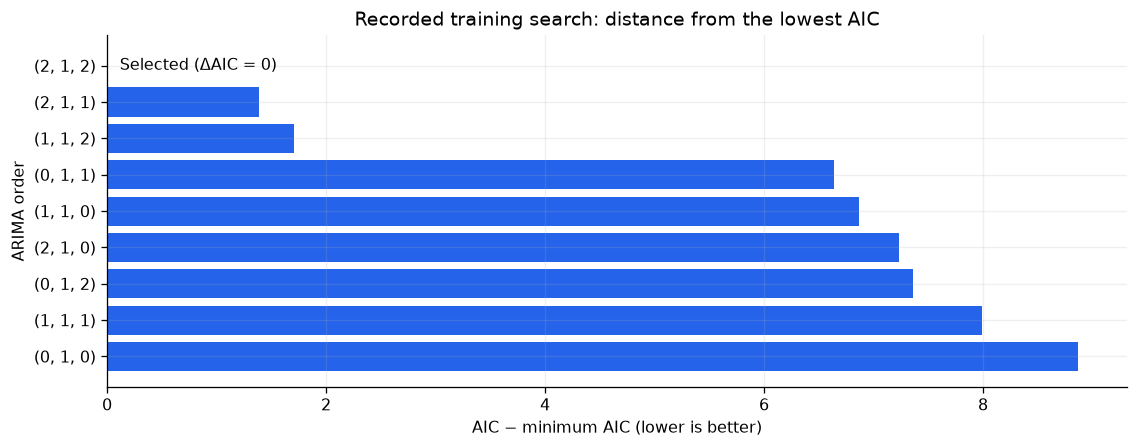

Selected AIC: 1756.733879471
Gap to next lowest AIC: 1.387089


In [8]:
candidates = pd.DataFrame(summary["candidates"])
assert candidates.order.tolist() == settings["orders"]
assert len(candidates) == 9
eligible = candidates.loc[candidates.eligible & candidates.converged & np.isfinite(candidates.aic)].copy()
# Verify the saved winner with the production rule, without refitting candidate models.
winner = min(eligible.to_dict("records"), key=lambda row: (row["aic"], row["order"][0] + row["order"][2], tuple(row["order"])))
assert tuple(winner["order"]) == selected_order
candidate_table = candidates.copy()
candidate_table["order"] = candidate_table.order.map(tuple)
candidate_table["delta_AIC"] = candidate_table.aic - winner["aic"]
candidate_table["selected"] = candidate_table.order.map(lambda order: order == selected_order)
candidate_table["warnings"] = candidate_table.warnings.map(lambda items: " | ".join(items) if items else "None")
display(candidate_table.sort_values("aic").reset_index(drop=True))
fig, ax = plt.subplots(figsize=(10, 4))
ordered = candidate_table.sort_values("aic")
ax.barh([str(order) for order in ordered.order], ordered.delta_AIC,
        color=[GREEN if chosen else BLUE for chosen in ordered.selected])
ax.invert_yaxis()
ax.set(title="Recorded training search: distance from the lowest AIC", xlabel="AIC − minimum AIC (lower is better)", ylabel="ARIMA order")
ax.annotate("Selected (ΔAIC = 0)", (0, 0), xytext=(8, 0), textcoords="offset points", va="center")
fig.tight_layout(); show_figure(fig)
print(f"Selected AIC: {winner['aic']:.9f}")
print(f"Gap to next lowest AIC: {ordered.aic.iloc[1] - ordered.aic.iloc[0]:.6f}")


All nine candidates are eligible and converged. **ARIMA(2,1,2)** has the lowest AIC, **1756.733879471**; the next candidate, (2,1,1), is only about **1.387** AIC units higher. This is a bounded ranking, not a decisive demonstration of a uniquely correct order.

Two candidates, including the winner, required fallback starting values for AR and MA parameters. These are recorded optimiser-initialisation warnings, not proof of a nonstationary fitted AR component. Convergence alone does not prove a global likelihood optimum or model adequacy. The same specification and warnings must be retained when reproducing the selected fit.

## 8. Fitting the selected ARIMA model

Fitting estimates the coefficients and innovation variance that maximise the model's training likelihood under its constraints. It uses **all 2,014 training prices**, not only the 1,984 thirty-session supervised examples. ARIMA is a state-space model with a filtered history, not a model restricted to the latest thirty-row input window.

The call below passes **only the recorded selected order** to the actual production fitting function. Its purpose is reproducibility and demonstration, not another selection decision. The reconstructed AIC, coefficients and warnings must agree with the saved fit before forecasts are evaluated. Original experiment files and their source hashes continue to identify the original run; current source hashes are not substituted into them.


In [9]:
fitted, reproduction_record = select_training_model(training.to_numpy(), [list(selected_order)], maxiter=settings["maxiter"])
assert fitted.model.order == selected_order and fitted.mle_retvals["converged"]
assert len(reproduction_record) == 1
assert reproduction_record[0]["warnings"] == winner["warnings"]
np.testing.assert_allclose(fitted.aic, winner["aic"], rtol=0, atol=1e-8)
recorded_params = np.array([summary["parameters"][name] for name in fitted.param_names])
np.testing.assert_allclose(fitted.params, recorded_params, rtol=0, atol=1e-10)
np.testing.assert_allclose(fitted.aic, 2 * fitted.df_model - 2 * fitted.llf, rtol=0, atol=1e-10)
parameter_table = pd.DataFrame({"parameter": fitted.param_names, "estimate": fitted.params,
                                "recorded_estimate": recorded_params, "model_based_standard_error": fitted.bse})
display(parameter_table)
display(pd.Series({"training_observations": fitted.nobs, "estimated_parameters_k": fitted.df_model,
                   "maximised_log_likelihood": fitted.llf, "AIC": fitted.aic,
                   "optimizer_converged": fitted.mle_retvals["converged"],
                   "initial_likelihood_burn": fitted.loglikelihood_burn}, name="Fit evidence").to_frame())
print("Retained fitting warnings:")
for message in reproduction_record[0]["warnings"]:
    print("•", message)


,parameter,estimate,recorded_estimate,model_based_standard_error
0,ar.L1,-1.706993,-1.706993,0.050631
1,ar.L2,-0.808298,-0.808298,0.047377
2,ma.L1,1.688583,1.688583,0.054980
3,ma.L2,0.774079,0.774079,0.052824
4,sigma2,0.139428,0.139428,0.001670


,Fit evidence
training_observations,2014
estimated_parameters_k,5
maximised_log_likelihood,-873.36694
AIC,1756.733879
optimizer_converged,True
initial_likelihood_burn,1


Retained fitting warnings:
• Non-invertible starting MA parameters found. Using zeros as starting parameters.
• Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.


The fitted lag coefficients are approximately $\phi_1=-1.707$, $\phi_2=-0.808$, $\theta_1=1.689$ and $\theta_2=0.774$. A coefficient larger than one in magnitude does not by itself invalidate a second-order AR model; the joint characteristic roots determine the stability constraint.

With the lag operator $Bw_t=w_{t-1}$, the equation can be written $\Phi(B)w_t=\Theta(B)\varepsilon_t$, where
\[
\Phi(B)=1-\phi_1B-\phi_2B^2\approx1+1.707B+0.808B^2,
\qquad\Theta(B)=1+\theta_1B+\theta_2B^2\approx1+1.689B+0.774B^2.
\]
The signs in the AR polynomial reverse when lagged values move to the left side of the equation. Its coefficients are therefore similar to those of the MA polynomial. Similar factors in the response $\Theta(B)/\Phi(B)$ partly offset each other. Consequently, large individual terms do not necessarily produce a large net forecast correction. This is a descriptive property of the fitted model, not proof of weak identification or a reason to reduce the order automatically. Standard errors are model-based and should be interpreted cautiously given the variability and residual diagnostics below.

### A numerical decomposition of the first forecast

For one demonstration only, substitute the final two observed changes and estimated training innovations into
\[
\widehat{\Delta C}_{t+1}=\phi_1\Delta C_t+\phi_2\Delta C_{t-1}
+\theta_1\hat\varepsilon_t+\theta_2\hat\varepsilon_{t-1}.
\]
The subsequent research forecasts still come from `rolling_one_step()`. This calculation verifies the meaning of its first prediction rather than creating another forecasting implementation.


In [10]:
root_table = pd.DataFrame({"AR_root_modulus": np.abs(fitted.arroots), "MA_root_modulus": np.abs(fitted.maroots)})
display(root_table)
assert (root_table > 1).all().all()
component_inputs = np.r_[changes.iloc[-1:-3:-1].to_numpy(), np.asarray(fitted.resid)[-1:-3:-1]]
component_coefficients = np.r_[fitted.arparams, fitted.maparams]
contributions = pd.DataFrame({"term": ["AR lag 1", "AR lag 2", "MA innovation lag 1", "MA innovation lag 2"],
                               "coefficient": component_coefficients, "historical_input_usd": component_inputs,
                               "contribution_usd": component_coefficients * component_inputs})
display(contributions)
explained_first_forecast = float(training.iloc[-1] + contributions.contribution_usd.sum())
display(Markdown(
    f"Latest observed Close: **{training.iloc[-1]:.6f} USD**. Summed correction: "
    f"**{contributions.contribution_usd.sum():+.6f} USD**. Reconstructed first forecast: "
    f"**{explained_first_forecast:.6f} USD**. The AR and MA terms partly cancel in this example."
))


,AR_root_modulus,MA_root_modulus
0,1.11228,1.136599
1,1.11228,1.136599


,term,coefficient,historical_input_usd,contribution_usd
0,AR lag 1,-1.706993,0.011001,-0.018778
1,AR lag 2,-0.808298,0.566999,-0.458305
2,MA innovation lag 1,1.688583,0.102054,0.172327
3,MA innovation lag 2,0.774079,0.509715,0.394559


Latest observed Close: **14.614000 USD**. Summed correction: **+0.089803 USD**. Reconstructed first forecast: **14.703804 USD**. The AR and MA terms partly cancel in this example.

## 9. Rolling one-step-ahead forecasting

The evaluation repeatedly performs:

**Training fit → forecast next Close → record forecast → observe that Close → update filtered state → forecast the next session.**

`rolling_one_step()` calls `state.forecast(steps=1)` **before** `state.extend([actual])`. `extend()` filters the new observation using the fitted parameters; it does not run another coefficient optimisation. The returned state carries forward information needed for the next forecast. [State-extension documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.extend.html).

The optional trace records the events and parameter values from that **same production loop**. Forecast events contain no target outcome. An update event includes the newly observed Close only after the prediction has been recorded. Dates are joined from the verified dataset metadata rather than invented from calendar-day offsets.

Validation closes are loaded within their explicit boundary and stored for sequential evaluation. Their presence in memory is not permission to supply them to an earlier forecast. Earlier validation observations become legitimate context only after their sessions close. This is different from issuing a single long-horizon forecast at the end of training, and from refitting coefficients on expanding validation data.


In [11]:
# Load only permitted development values after the training-only analysis and fitting.
development = load_yahoo_snapshot(raw_path, start=config["start"], end=config["validation_end"])["close"]
coverage = audit_sessions(development.index, config["start"], config["validation_end"], settings["calendar"])
assert not coverage["missing"] and not coverage["unexpected"]
assert coverage["ordered"] and coverage["duplicate_dates"] == 0
assert coverage == summary["calendar_audit"]
np.testing.assert_array_equal(development.loc[:TRAIN_END], training)
dataset = build_development_dataset(development, config)
mask = dataset.metadata.split.eq("validation").to_numpy()
validation_close = development.loc[development.index > TRAIN_END]
metadata = dataset.metadata.loc[mask, ["origin_date", "target_date"]].reset_index(drop=True)
np.testing.assert_array_equal(metadata.target_date.to_numpy(), validation_close.index.to_numpy())
assert len(metadata) == 502 and metadata.target_date.max() <= VALIDATION_END
assert (metadata.origin_date < metadata.target_date).all()

trace = []
parameters_before = fitted.params.copy()
arima_forecasts = rolling_one_step(fitted, validation_close.to_numpy(), trace=trace)
naive_forecasts = naive_predictions(dataset)[mask]
np.testing.assert_array_equal(fitted.params, parameters_before)
np.testing.assert_allclose(arima_forecasts[0], explained_first_forecast, rtol=0, atol=1e-8)
assert len(trace) == 2 * len(metadata)
for step in range(len(metadata)):
    forecast_event, update_event = trace[2 * step:2 * step + 2]
    assert (forecast_event["event"], update_event["event"]) == ("forecast", "update")
    assert forecast_event["step"] == update_event["step"] == step
    assert "observed_close" not in forecast_event
    assert forecast_event["prediction"] == arima_forecasts[step]
    assert update_event["observed_close"] == validation_close.iloc[step]
    np.testing.assert_array_equal(forecast_event["parameters"], parameters_before)
    np.testing.assert_array_equal(update_event["parameters"], parameters_before)

validation = metadata.copy()
validation["actual_close"] = validation_close.to_numpy()
validation["arima_prediction"] = arima_forecasts
validation["naive_prediction"] = naive_forecasts
validation["arima_error_usd"] = arima_forecasts - validation.actual_close
validation["naive_error_usd"] = naive_forecasts - validation.actual_close
validation["year"] = validation.target_date.dt.year
print(f"Verified {len(trace):,} ordered events: {len(metadata)} forecasts followed by {len(metadata)} state updates, with fixed coefficients.")


Verified 1,004 ordered events: 502 forecasts followed by 502 state updates, with fixed coefficients.


,step,event,origin_date,target_date,information_available_through,forecast_usd,new_observation_usd,parameters_equal_training_fit
0,1,forecast,2022-12-30,2023-01-03,2022-12-30,14.703804,NaN,True
1,1,update,2022-12-30,2023-01-03,2023-01-03,NaN,14.315,True
2,2,forecast,2023-01-03,2023-01-04,2023-01-03,14.238970,NaN,True
3,2,update,2023-01-03,2023-01-04,2023-01-04,NaN,14.749,True
4,3,forecast,2023-01-04,2023-01-05,2023-01-04,14.810109,NaN,True
5,3,update,2023-01-04,2023-01-05,2023-01-05,NaN,14.265,True


,origin_date,target_date,arima_prediction,actual_close,arima_error_usd,naive_prediction
0,2022-12-30,2023-01-03,14.703804,14.315,0.388804,14.614
1,2023-01-03,2023-01-04,14.238970,14.749,-0.510030,14.315
2,2023-01-04,2023-01-05,14.810109,14.265,0.545109,14.749
3,2023-01-05,2023-01-06,14.214724,14.859,-0.644276,14.265
4,2023-01-06,2023-01-09,14.902219,15.628,-0.725781,14.859


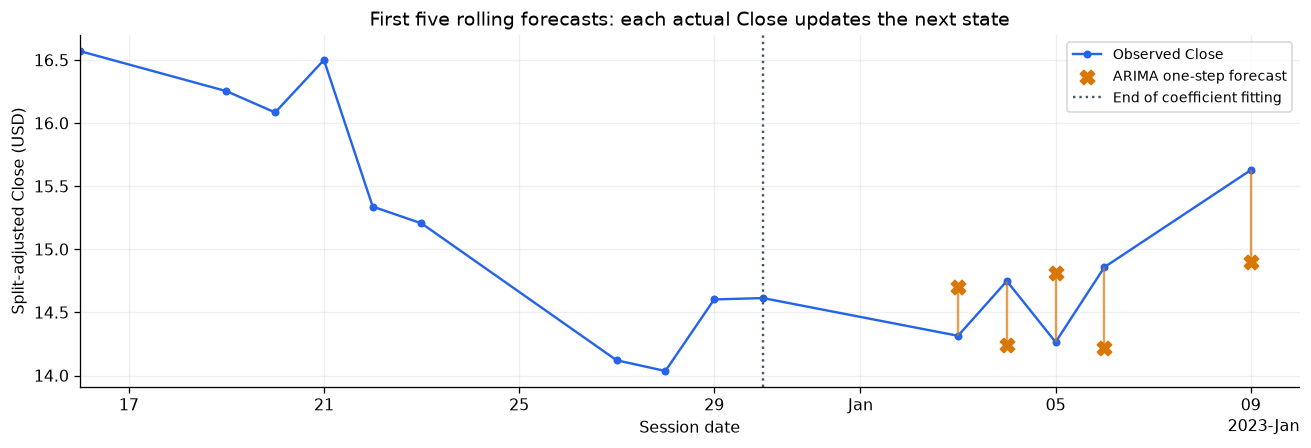

**First forecast:** origin **2022-12-30**, target **2023-01-03**. ARIMA predicts **14.703804 USD**, compared with an eventual Close of **14.315000 USD**: signed error **+0.388804 USD** (prediction minus actual). The second forecast incorporates that observed target, while every coefficient remains equal to the training estimate.

In [12]:
event_rows = []
for event in trace[:6]:
    step = event["step"]
    dates = metadata.iloc[step]
    is_forecast = event["event"] == "forecast"
    event_rows.append({"step": step + 1, "event": event["event"], "origin_date": dates.origin_date,
                       "target_date": dates.target_date,
                       "information_available_through": dates.origin_date if is_forecast else dates.target_date,
                       "forecast_usd": event.get("prediction", np.nan),
                       "new_observation_usd": event.get("observed_close", np.nan),
                       "parameters_equal_training_fit": np.array_equal(event["parameters"], parameters_before)})
display(pd.DataFrame(event_rows))
first_forecasts = validation.head(5)
display(first_forecasts[["origin_date", "target_date", "arima_prediction", "actual_close", "arima_error_usd", "naive_prediction"]])
fig, ax = plt.subplots(figsize=(11.5, 4))
context = training.tail(10)
observed_path = pd.concat([context, validation_close.head(5)])
ax.plot(observed_path.index, observed_path, color=BLUE, marker="o", markersize=4, label="Observed Close")
ax.scatter(first_forecasts.target_date, first_forecasts.arima_prediction, color=ORANGE, marker="X", s=80, label="ARIMA one-step forecast", zorder=4)
ax.vlines(first_forecasts.target_date, first_forecasts.actual_close, first_forecasts.arima_prediction, color=ORANGE, alpha=.7)
ax.axvline(training.index.max(), color="#475569", linestyle=":", label="End of coefficient fitting")
ax.set(title="First five rolling forecasts: each actual Close updates the next state", xlabel="Session date", ylabel="Split-adjusted Close (USD)")
dated_axis(ax, observed_path.index.min(), observed_path.index.max() + pd.Timedelta(days=1))
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout(); show_figure(fig)
first = validation.iloc[0]
display(Markdown(
    f"**First forecast:** origin **{first.origin_date.date()}**, target **{first.target_date.date()}**. "
    f"ARIMA predicts **{first.arima_prediction:.6f} USD**, compared with an eventual Close of "
    f"**{first.actual_close:.6f} USD**: signed error **{first.arima_error_usd:+.6f} USD** "
    "(prediction minus actual). The second forecast incorporates that observed target, "
    "while every coefficient remains equal to the training estimate."
))


The trace establishes forecast/update ordering inside the actual implementation and parameter equality at every step. Separate automated tests use controlled event logs and perturbed future observations to check that a future target cannot affect its own or earlier forecasts. Neither successful execution nor a narrative diagram alone would establish this safeguard.

## 10. Forecast evaluation and benchmark comparison

Both models forecast the **same 502 target dates**, 3 January 2023 through 31 December 2024, on the same price basis and information schedule. Define $e_i=\hat y_i-y_i$:
\[
MAE=\frac1n\sum_i|e_i|,\qquad RMSE=\sqrt{\frac1n\sum_i e_i^2}.
\]
Both metrics are in USD; RMSE gives more weight to large misses. Lower values are preferable on identical dates, but do not establish trading profitability.

The relative increase in ARIMA MAE is
\[
100\left(\frac{MAE_{ARIMA}}{MAE_{naive}}-1\right).
\]
A positive value means worse accuracy by this metric. The saved field `mae_improvement_pct` uses the opposite sign, so a negative recorded improvement means the same deterioration.

We compare all reconstructed dates and values with the saved ARIMA and naïve predictions before reporting scores. JSON prices have ten-decimal serialization, so a 1e-9 USD comparison tolerance accommodates that rounding; the full-precision aggregate metrics are checked at 1e-10 USD. Discrepancies stop execution rather than replacing evidence.


In [13]:
saved_arima = pd.DataFrame(json.loads((run_dir / "validation_predictions.json").read_text()))
saved_naive = pd.DataFrame(json.loads((ROOT / "artifacts/naive_v1/validation_predictions.json").read_text()))
for stored in [saved_arima, saved_naive]:
    for col in ["origin_date", "target_date"]:
        stored[col] = pd.to_datetime(stored[col])
        np.testing.assert_array_equal(metadata[col].to_numpy(), stored[col].to_numpy())
for column in ["actual_close", "arima_prediction", "naive_prediction"]:
    np.testing.assert_allclose(validation[column], saved_arima[column], rtol=0, atol=1e-9)
np.testing.assert_allclose(validation.naive_prediction, saved_naive.prediction, rtol=0, atol=1e-9)
np.testing.assert_allclose(validation.actual_close, saved_naive.actual_close, rtol=0, atol=1e-9)
metrics = {"ARIMA": error_metrics(validation.actual_close, validation.arima_prediction),
           "Naïve": error_metrics(validation.actual_close, validation.naive_prediction)}
for model, recorded_name in [("ARIMA", "arima"), ("Naïve", "naive")]:
    assert metrics[model]["n"] == summary["validation_metrics"][recorded_name]["n"]
    for name in ["mae_usd", "rmse_usd"]:
        np.testing.assert_allclose(metrics[model][name], summary["validation_metrics"][recorded_name][name], rtol=0, atol=1e-10)
naive_summary = json.loads((ROOT / "artifacts/naive_v1/summary.json").read_text())
for name in ["mae_usd", "rmse_usd"]:
    np.testing.assert_allclose(metrics["Naïve"][name], naive_summary["validation_metrics"][name], rtol=0, atol=1e-10)
mae_increase_pct = 100 * (metrics["ARIMA"]["mae_usd"] / metrics["Naïve"]["mae_usd"] - 1)
np.testing.assert_allclose(mae_increase_pct, -summary["mae_improvement_pct"], rtol=0, atol=1e-10)
display(pd.DataFrame(metrics).T)
print(f"ARIMA MAE increase: {mae_increase_pct:.6f}%")
print(f"Maximum difference from stored ARIMA forecasts: {abs(validation.arima_prediction - saved_arima.arima_prediction).max():.3e} USD")


,n,mae_usd,rmse_usd
ARIMA,502.0,1.720201,2.612846
Naïve,502.0,1.689494,2.589324


ARIMA MAE increase: 1.817494%
Maximum difference from stored ARIMA forecasts: 4.992e-11 USD


**Result:** naïve MAE/RMSE are **1.689494 / 2.589324 USD**; ARIMA values are **1.720201 / 2.612846 USD**. ARIMA MAE is approximately **1.82% higher**. The AIC-selected model does not improve this validation benchmark. This is an empirical comparison over the specified interval, not a claim of statistical significance or universal superiority of persistence.

## 11. Forecast diagnostics and error analysis

### Price paths and validation errors

The full path shows price-level changes; a predefined first-thirty-target view makes the one-step predictions easier to inspect. Close visual tracking is expected for persistent levels, so the price chart is interpreted alongside errors, not as evidence of forecasting skill.


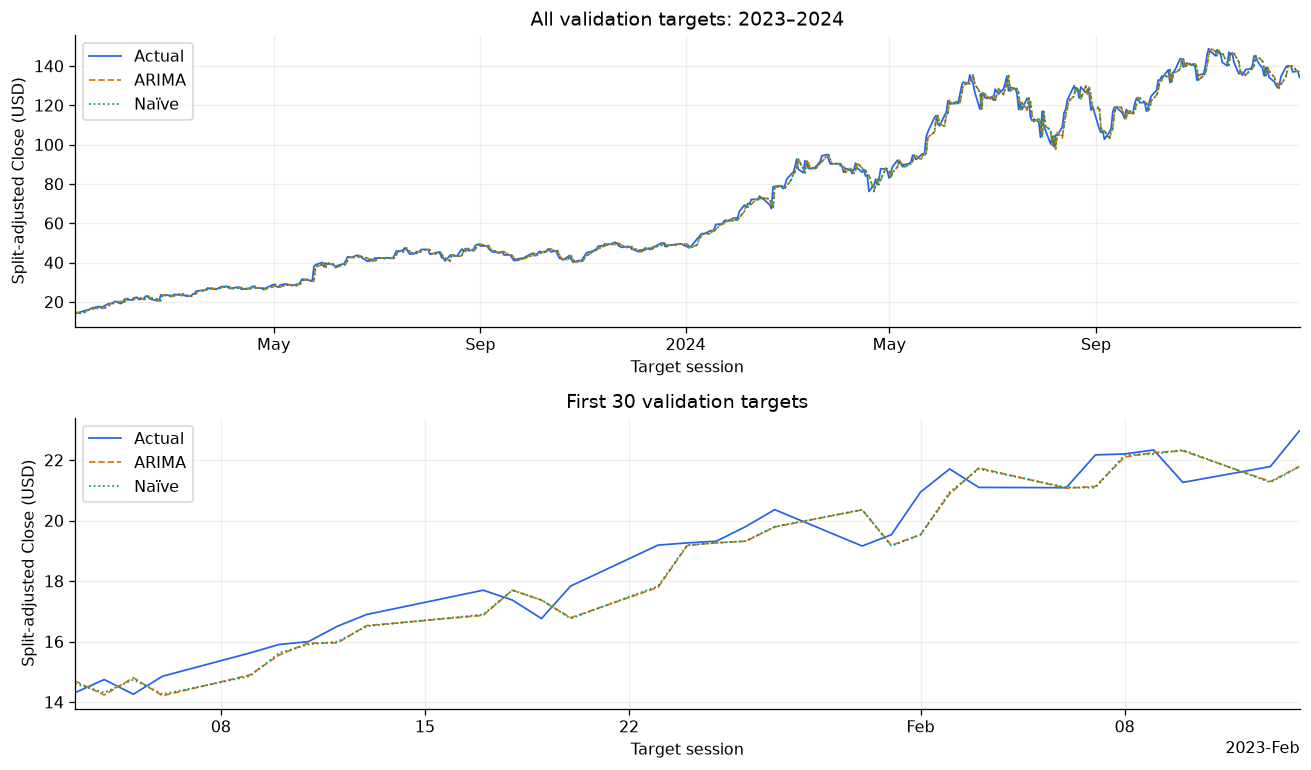

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(11.5, 6.8))
for ax, frame, title in [(axes[0], validation, "All validation targets: 2023–2024"),
                         (axes[1], validation.head(30), "First 30 validation targets")]:
    for column, label, color, style in [("actual_close", "Actual", BLUE, "-"),
                                        ("arima_prediction", "ARIMA", ORANGE, "--"),
                                        ("naive_prediction", "Naïve", GREEN, ":")]:
        ax.plot(frame.target_date, frame[column], label=label, color=color, linestyle=style, linewidth=1.1)
    ax.set(title=title, xlabel="Target session", ylabel="Split-adjusted Close (USD)")
    dated_axis(ax, frame.target_date.min(), frame.target_date.max())
    ax.legend(loc="upper left")
fig.tight_layout(); show_figure(fig)


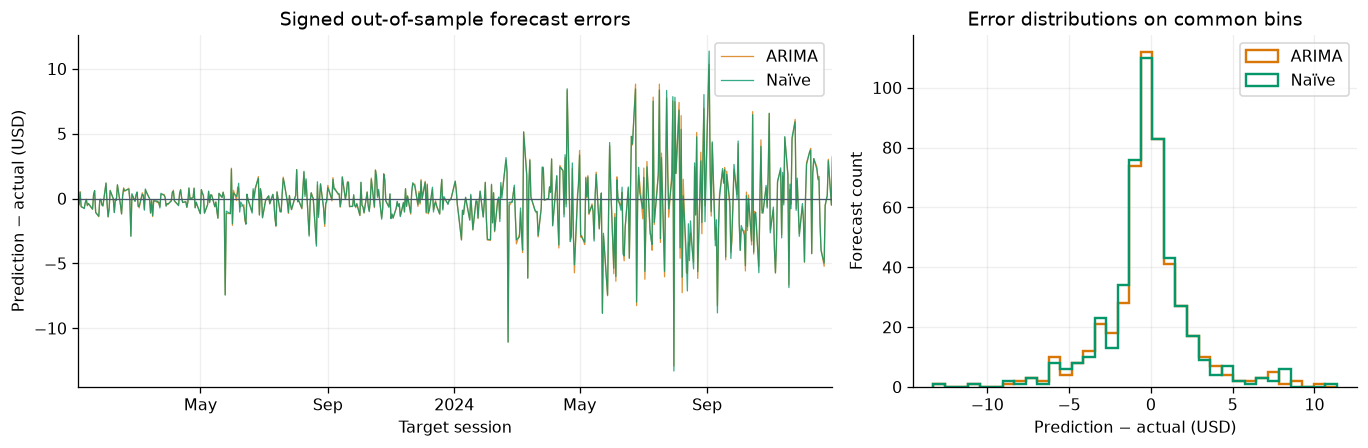

,target_date,actual_close,arima_prediction,arima_error_usd,naive_error_usd,arima_correction_usd
395,2024-07-31 00:00:00,117.019997,104.105619,-12.914378,-13.289993,0.375615
285,2024-02-22 00:00:00,78.538002,67.481216,-11.056786,-11.066002,0.009216
418,2024-09-03 00:00:00,108.000000,118.346340,10.346340,11.370003,-1.023663
369,2024-06-24 00:00:00,118.110001,126.942292,8.832292,8.459999,0.372293
385,2024-07-17 00:00:00,117.989998,126.818367,8.828369,8.370003,0.458366


Days with smaller ARIMA absolute error: 244 / 502
Mean paired absolute-error difference (ARIMA − naïve): +0.030706 USD


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.7, 1]})
bins = np.histogram_bin_edges(np.r_[validation.arima_error_usd, validation.naive_error_usd], bins=35)
for column, label, color in [("arima_error_usd", "ARIMA", ORANGE), ("naive_error_usd", "Naïve", GREEN)]:
    axes[0].plot(validation.target_date, validation[column], label=label, color=color, linewidth=.8, alpha=.8)
    axes[1].hist(validation[column], bins=bins, label=label, color=color, histtype="step", linewidth=1.5)
axes[0].axhline(0, color="#475569", linewidth=.8)
axes[0].set(title="Signed out-of-sample forecast errors", xlabel="Target session", ylabel="Prediction − actual (USD)")
dated_axis(axes[0], validation.target_date.min(), validation.target_date.max())
axes[1].set(title="Error distributions on common bins", xlabel="Prediction − actual (USD)", ylabel="Forecast count")
for ax in axes: ax.legend()
fig.tight_layout(); show_figure(fig)

validation["absolute_error_difference_usd"] = validation.arima_error_usd.abs() - validation.naive_error_usd.abs()
validation["arima_correction_usd"] = validation.arima_prediction - validation.naive_prediction
validation["observed_change_usd"] = validation.actual_close - validation.naive_prediction
# Decompose ARIMA errors into persistence's miss plus the fitted correction.
np.testing.assert_allclose(validation.arima_error_usd, validation.naive_error_usd + validation.arima_correction_usd, rtol=0, atol=1e-12)
worst = validation.loc[validation.arima_error_usd.abs().nlargest(5).index,
    ["target_date", "actual_close", "arima_prediction", "arima_error_usd", "naive_error_usd", "arima_correction_usd"]]
display(worst.style.format({c: "{:.6f}" for c in worst.select_dtypes("number").columns}))
print(f"Days with smaller ARIMA absolute error: {(validation.absolute_error_difference_usd < 0).sum()} / {len(validation)}")
print(f"Mean paired absolute-error difference (ARIMA − naïve): {validation.absolute_error_difference_usd.mean():+.6f} USD")


For any one-step ARIMA forecast, define its correction relative to persistence as $a_{t+1}=\hat C^{ARIMA}_{t+1}-C_t$. Then
\[
e^{ARIMA}_{t+1}=-\Delta C_{t+1}+a_{t+1}.
\]
This identity explains why both models can experience large misses on large dollar moves. It does not prove why the estimated correction succeeds or fails. Counting days won ignores the magnitude of other misses; average paired error differences and full-period metrics supply that information. The largest-error rows are retained rather than deleted as outliers.

### Annual comparisons and changing dollar scale

Use the same evaluation function within each year. Aggregate MAE is the count-weighted annual MAE; aggregate RMSE requires averaging **squared** annual RMSE before taking the square root. Mean absolute observed percentage movement is a descriptive scale comparison using the origin Close as denominator, not a new selection metric.


n   mae_usd  rmse_usd
year model                         
2023 Naïve  250  0.730728  1.022887
     ARIMA  250  0.736197  1.022374
2024 Naïve  252  2.640651  3.509699
     ARIMA  252  2.696395  3.544404

,mean_origin_close_usd,sd_observed_change_usd,mean_absolute_change_pct_of_origin
year,,,
2023,36.429628,1.015345,2.138067
2024,107.489079,3.500495,2.490152


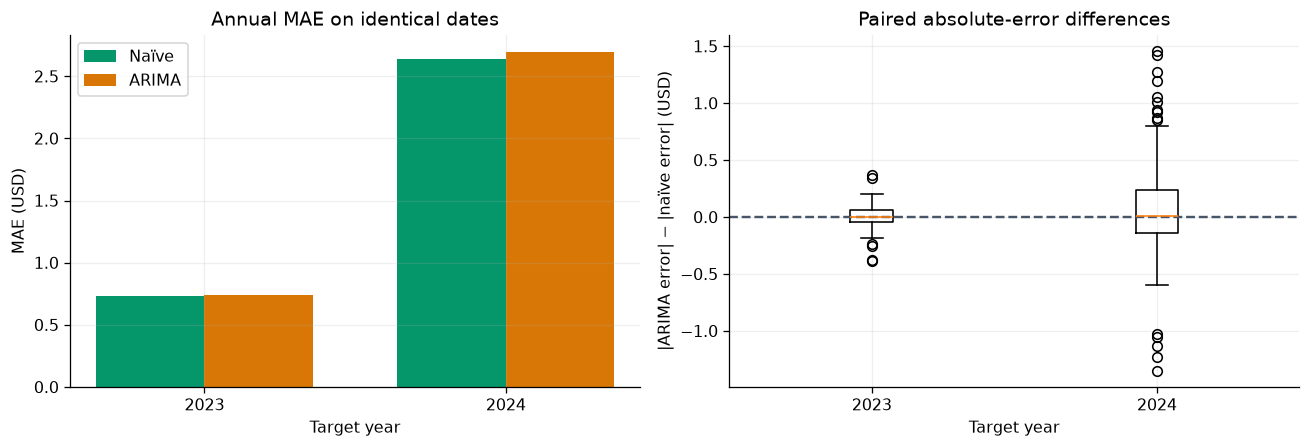

In [16]:
annual_rows = []
for year, group in validation.groupby("year"):
    for model, column in [("Naïve", "naive_prediction"), ("ARIMA", "arima_prediction")]:
        annual_rows.append({"year": int(year), "model": model, **error_metrics(group.actual_close, group[column])})
annual = pd.DataFrame(annual_rows)
display(annual.set_index(["year", "model"]))
scale_by_year = validation.groupby("year").apply(lambda g: pd.Series({
    "mean_origin_close_usd": g.naive_prediction.mean(),
    "sd_observed_change_usd": g.observed_change_usd.std(),
    "mean_absolute_change_pct_of_origin": (100 * g.observed_change_usd.abs() / g.naive_prediction).mean(),
}))
display(scale_by_year)
for model, group in annual.groupby("model"):
    np.testing.assert_allclose(np.average(group.mae_usd, weights=group.n), metrics[model]["mae_usd"])
    np.testing.assert_allclose(np.sqrt(np.average(group.rmse_usd ** 2, weights=group.n)), metrics[model]["rmse_usd"])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
years = sorted(validation.year.unique())
positions = np.arange(len(years))
for offset, model, color in [(-.18, "Naïve", GREEN), (.18, "ARIMA", ORANGE)]:
    rows = annual.loc[annual.model.eq(model)].set_index("year").loc[years]
    axes[0].bar(positions + offset, rows.mae_usd, .36, color=color, label=model)
axes[0].set_xticks(positions, [str(y) for y in years])
axes[0].set(title="Annual MAE on identical dates", xlabel="Target year", ylabel="MAE (USD)")
axes[0].legend()
axes[1].boxplot([validation.loc[validation.year.eq(y), "absolute_error_difference_usd"] for y in years], tick_labels=[str(y) for y in years])
axes[1].axhline(0, color="#475569", linestyle="--")
axes[1].set(title="Paired absolute-error differences", xlabel="Target year", ylabel="|ARIMA error| − |naïve error| (USD)")
fig.tight_layout(); show_figure(fig)


ARIMA MAE is higher in both years. In 2023 its RMSE is very slightly lower (about **1.022374 versus 1.022887 USD**); in 2024 both metrics are higher. The combined results therefore do not justify saying ARIMA loses on every metric in every subperiod.

Both models' dollar errors are much larger in 2024, alongside higher price levels and dollar variability. Relative movements also change, but by a different proportion. These descriptive associations do not isolate the reason for underperformance. No significance test comparing forecasting models is performed; paired sequential errors are not assumed independent.

### Training innovations are not validation forecast errors

A training innovation is $v_t=C_t-\hat C_{t|t-1}$, using the model's one-step prediction within its training sample. It has the **opposite sign** to our prediction-minus-actual validation errors. Moreover, its coefficients were estimated using the whole training period, so these are fitting diagnostics, not honest out-of-sample historical forecasts.

We exclude the model's initial likelihood/diffuse-state burn-in and inspect standardised innovations, $v_t/\sqrt{F_t}$, where $F_t$ is the fitted one-step prediction variance. Standardisation by that model variance does not guarantee empirically constant volatility. Raw-innovation annual SD remains in USD for comparison with training dollar changes.

Ljung–Box tests at fixed lags **10 and 20** use `model_df=p+q=4`, giving reference degrees of freedom 6 and 16. Their null is no autocorrelation through the stated lag, under the diagnostic assumptions. Small p-values challenge that adequacy condition; large ones would not prove independence. Changing volatility, parameter estimation and the bounded search affect interpretation. The squared-innovation ACF and normal Q–Q plot are descriptive, not additional model-selection rules. [Ljung–Box documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html).


,lb_stat,lb_pvalue,reference_df
10,24.334482,4.532019e-04,6
20,58.856585,8.145789e-07,16


,observations,sd_innovation_usd
date,,
2015,251,0.012945
2016,252,0.047640
2017,251,0.090064
2018,251,0.167095
2019,252,0.105884
2020,253,0.310416
2021,252,0.619645
2022,251,0.762423


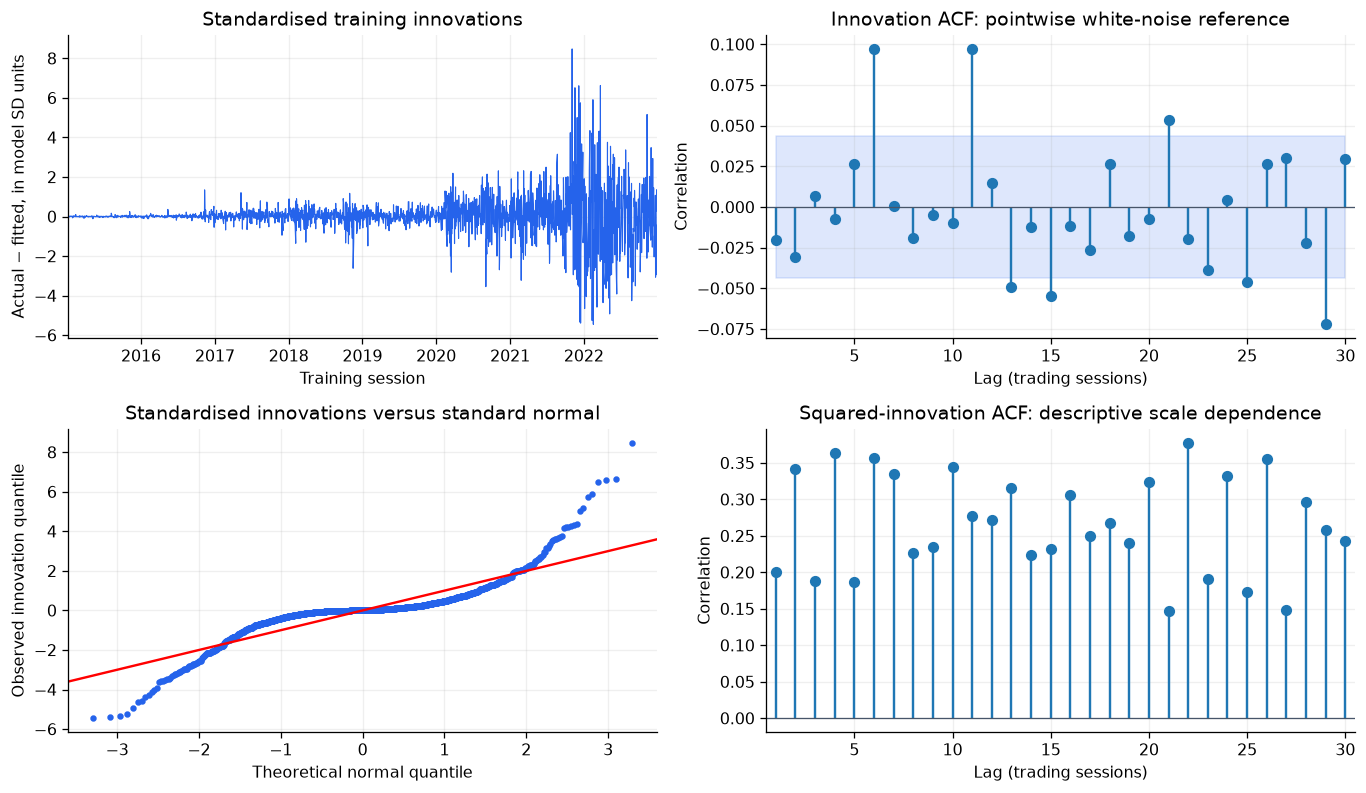

**Residual evidence:** 1 initial observation(s) excluded by the fitted initialisation; 2,013 innovations remain. Ljung–Box p-values are **0.000453** at lag 10 and **8.15e-07** at lag 20. Both are below 0.05, challenging the absence of remaining linear autocorrelation under these tests. Raw innovation SD changes from **0.012945** to **0.762423 USD** across training years; lag-one squared-innovation ACF is **0.200**. The changing spread and Q–Q departures caution against treating innovations as independent, constant-variance Gaussian noise. These diagnostics do not by themselves explain validation underperformance or authorise another model search.

In [17]:
burn = max(int(fitted.loglikelihood_burn), int(fitted.filter_results.nobs_diffuse))
innovation_dates = training.index[burn:]
raw_innovations = pd.Series(np.asarray(fitted.resid)[burn:], index=innovation_dates)
standardized_innovations = pd.Series(fitted.filter_results.standardized_forecasts_error[0, burn:], index=innovation_dates)
assert np.isfinite(standardized_innovations).all()
lb = acorr_ljungbox(standardized_innovations, lags=[10, 20], model_df=selected_order[0] + selected_order[2], return_df=True)
lb["reference_df"] = lb.index - selected_order[0] - selected_order[2]
display(lb)
innovation_years = raw_innovations.groupby(raw_innovations.index.year).agg(observations="size", sd_innovation_usd="std")
display(innovation_years)
residual_acf, residual_ci = acf(standardized_innovations, nlags=LAGS, alpha=.05, bartlett_confint=False, result_object=False)
squared_acf = acf(standardized_innovations ** 2, nlags=LAGS, result_object=False)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].plot(innovation_dates, standardized_innovations, color=BLUE, linewidth=.7)
axes[0, 0].set(title="Standardised training innovations", xlabel="Training session", ylabel="Actual − fitted, in model SD units")
dated_axis(axes[0, 0], innovation_dates.min(), innovation_dates.max())
correlation_panel(axes[0, 1], residual_acf, residual_ci, "Innovation ACF: pointwise white-noise reference")
qqplot(standardized_innovations, line="45", ax=axes[1, 0], markerfacecolor=BLUE, markeredgecolor=BLUE, markersize=3)
axes[1, 0].set(title="Standardised innovations versus standard normal", xlabel="Theoretical normal quantile", ylabel="Observed innovation quantile", xlim=(-3.6, 3.6))
correlation_panel(axes[1, 1], squared_acf, None, "Squared-innovation ACF: descriptive scale dependence")
fig.tight_layout(); show_figure(fig)
display(Markdown(
    f"**Residual evidence:** {burn} initial observation(s) excluded by the fitted initialisation; "
    f"{len(standardized_innovations):,} innovations remain. Ljung–Box p-values are "
    f"**{lb.loc[10, 'lb_pvalue']:.3g}** at lag 10 and **{lb.loc[20, 'lb_pvalue']:.3g}** at lag 20. "
    "Both are below 0.05, challenging the absence of remaining linear autocorrelation under these tests. "
    f"Raw innovation SD changes from **{innovation_years.sd_innovation_usd.iloc[0]:.6f}** "
    f"to **{innovation_years.sd_innovation_usd.iloc[-1]:.6f} USD** across training years; "
    f"lag-one squared-innovation ACF is **{squared_acf[1]:.3f}**. "
    "The changing spread and Q–Q departures caution against treating innovations as independent, "
    "constant-variance Gaussian noise. These diagnostics do not by themselves explain validation underperformance "
    "or authorise another model search."
))


## 12. Research findings and methodological implications

The evidence supports the implementation's **training-only selection, fixed-parameter state updates and aligned evaluation**. It also identifies statistical limitations of the fitted benchmark: first differencing reduces level persistence, but does not eliminate changing variability or all residual correlation. Correct forecast timing and complete optimisation convergence are different from an adequate predictive model.

- **Selection:** (2,1,2) minimises recorded training AIC among nine eligible fixed candidates. Nearby AIC values and residual diagnostics limit any claim of a uniquely correct specification.
- **Forecast timing:** each forecast precedes incorporation of its own target, and all 502 updates preserve the fitted coefficients. The first target is 3 January 2023, following the 30 December 2022 origin.
- **Comparison:** both models use identical validation targets and USD conventions. ARIMA has higher full-period MAE and RMSE; it does not add demonstrated improvement over persistence in this comparison.
- **Implementation:** the production runner verifies snapshot identity, loads quote values only within development bounds and checks session coverage. Optional event tracing observes the production rolling loop without changing its forecasts. The core ARIMA specification, optimiser, candidate set and forecast arithmetic are retained.
- **Limits:** historical vendor adjustments are not point-in-time quotes; training diagnostics and validation scores cannot establish final-test performance, statistical significance, causal explanations or trading profitability.

An LSTM is a relevant next comparator because it can represent nonlinear sequence relationships. That flexibility introduces its own optimisation, regularisation, scaling and overfitting risks. It must use the same information timing and comparable evaluation dates, and it may fail to improve on these benchmarks. Alternative ARIMA transformations, drift, orders or refitting schedules would require a separately justified protocol; none is introduced here.


In [18]:
verification = pd.Series({
    "training fit uses permitted observations": fitted.nobs == len(training) and training.index.max() <= TRAIN_END,
    "recorded candidate set preserved": candidates.order.tolist() == settings["orders"],
    "recorded AIC winner reproduced": tuple(winner["order"]) == fitted.model.order == (2, 1, 2),
    "exact validation date alignment": np.array_equal(metadata.target_date.to_numpy(), saved_arima.target_date.to_numpy()),
    "forecast then update trace complete": len(trace) == 2 * len(validation),
    "parameters unchanged after every update": all(np.array_equal(event["parameters"], parameters_before) for event in trace),
    "no reserved target constructed": validation.target_date.max() <= VALIDATION_END,
    "ARIMA MAE reproduced": np.isclose(metrics["ARIMA"]["mae_usd"], summary["validation_metrics"]["arima"]["mae_usd"], rtol=0, atol=1e-10),
    "ARIMA RMSE reproduced": np.isclose(metrics["ARIMA"]["rmse_usd"], summary["validation_metrics"]["arima"]["rmse_usd"], rtol=0, atol=1e-10),
    "naive benchmark reproduced": np.isclose(metrics["Naïve"]["mae_usd"], naive_summary["validation_metrics"]["mae_usd"], rtol=0, atol=1e-10),
}, name="Passed")
assert verification.all()
display(verification.to_frame())
display(Markdown(
    f"**Verified comparison:** ARIMA MAE **{metrics['ARIMA']['mae_usd']:.9f} USD**, "
    f"RMSE **{metrics['ARIMA']['rmse_usd']:.9f} USD**; naïve MAE "
    f"**{metrics['Naïve']['mae_usd']:.9f} USD**, RMSE **{metrics['Naïve']['rmse_usd']:.9f} USD**. "
    f"The MAE increase is **{mae_increase_pct:.6f}%** across {len(validation)} aligned targets. "
    "Original experimental evidence remains unchanged."
))


,Passed
training fit uses permitted observations,True
recorded candidate set preserved,True
recorded AIC winner reproduced,True
exact validation date alignment,True
forecast then update trace complete,True
parameters unchanged after every update,True
no reserved target constructed,True
ARIMA MAE reproduced,True
ARIMA RMSE reproduced,True
naive benchmark reproduced,True


**Verified comparison:** ARIMA MAE **1.720200573 USD**, RMSE **2.612846480 USD**; naïve MAE **1.689494114 USD**, RMSE **2.589323812 USD**. The MAE increase is **1.817494%** across 502 aligned targets. Original experimental evidence remains unchanged.

Supporting research records: [benchmark methodology](../docs/MILESTONE_4.md), [data conventions](../docs/DATA_CONVENTIONS.md), [recorded search and results](../docs/arima_validation_v1.json). Authoritative implementation: [arima.py](../src/market_forecasting/arima.py), with [automated protocol checks](../tests/test_arima.py).
